# Goal & Plan
1. Follow along chapter 4 https://d2l.ai/chapter_linear-classification/index.html - write down Softmax Regression model in torch
2. Add non-linearityy (MLP with ReLU - going a little ahead cause Chapter 5 is about Multilayer Perceptrons but I already got to know them a little).
3. Compare results on validation set
4. Visualize differences

In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Load and explore

In [ ]:
import torch
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
import matplotlib.pyplot as plt
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F

In [ ]:
LR = 0.1
BATCH_SIZE=128

In [ ]:
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,))
])

train_dataset = datasets.FashionMNIST(
    root='./data',
    train=True,
    download=True,
    transform=transform
)


test_dataset = datasets.FashionMNIST(
    root='./data',
    train=False,
    download=True,
    transform=transform
)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False)

print(f"Training set size: {len(train_dataset)}")
print(f"Test set size: {len(test_dataset)}")

In [ ]:
labels = ['t-shirt', 'trouser', 'pullover', 'dress', 'coat',
              'sandal', 'shirt', 'sneaker', 'bag', 'ankle boot']

fig, axs = plt.subplots(2, 5, figsize=(12, 5))
fig.suptitle('One Sample Image per FashionMNIST Class', fontsize=16)

for i, label in enumerate(labels):
    target_idx = np.where(train_dataset.targets == i)[0][0]
    img, _ = train_dataset[target_idx]
    
    row, col = i // 5, i % 5
    axs[row, col].imshow(img.squeeze())
    axs[row, col].set_title(label, fontsize=10)
    axs[row, col].axis('off')

plt.tight_layout()
plt.show()

# Linear

In [ ]:
class Classifier(nn.Module):
    def __init__(self, lr = LR):
         super().__init__()
         self.lr = lr
         self.loss = nn.CrossEntropyLoss()

    def validation_step(self, batch):
        X, y = batch
        y_hat = self(X)
        l = self.loss(y_hat, y)
        return l

    def configure_optimizers(self):
        return optim.SGD(self.parameters(), lr = self.lr)

    def accuracy(self, Y_hat, Y, averaged=True):
        Y_hat = Y_hat.reshape((-1, Y_hat.shape[-1]))
        preds = Y_hat.argmax(axis=1).type(Y.dtype)
        compare = (preds == Y.reshape(-1)).type(torch.float32)
        return compare.mean() if averaged else compare

In [ ]:
def softmax(X):
    X_exp = torch.exp(X)
    partition = X_exp.sum(1, keepdims=True)
    return X_exp / partition

In [ ]:
class SoftmaxRegressionScratch(Classifier):
    def __init__(self, num_inputs, num_outputs, lr, sigma=0.01):
        super().__init__()
        self.W = torch.normal(0, sigma, size=(num_inputs, num_outputs),
                              requires_grad=True)
        self.b = torch.zeros(num_outputs, requires_grad=True)

    def parameters(self):
        return [self.W, self.b]

    def forward(self, X):
        X = X.reshape((-1, self.W.shape[0]))
        return softmax(X @ self.W + self.b)

In [ ]:
def evaluate(model, loader):
    model.eval()
    total_loss = 0.0
    total_acc = 0.0
    num_samples = 0
    
    with torch.no_grad():
        for batch in loader:
            X, y = batch
            loss = model.validation_step((X, y))
            total_loss += loss.item() * y.size(0)
            total_acc += (model.accuracy(model(X), y) * y.size(0)).item()
            num_samples += y.size(0)
    
    return total_loss / num_samples, total_acc / num_samples

def train_model(model, num_epochs=10, train_loader=train_loader, test_loader=test_loader):
    optimizer = model.configure_optimizers() 
    train_losses, train_accs = [], []
    val_losses, val_accs = [], []
    
    for epoch in range(num_epochs):
        model.train() 
        train_loss = 0.0
        train_acc = 0.0
        num_samples = 0
        
        for X, y in train_loader:
            optimizer.zero_grad()
            y_hat = model(X)
            loss = model.loss(y_hat, y)
            loss.backward()
            optimizer.step()
            
            train_loss += loss.item() * y.size(0)
            train_acc += (model.accuracy(y_hat, y) * y.size(0)).item()
            num_samples += y.size(0)
        
        avg_train_loss = train_loss / num_samples
        avg_train_acc = train_acc / num_samples
        train_losses.append(avg_train_loss)
        train_accs.append(avg_train_acc)
        print(f'Epoch {epoch+1}/{num_epochs}: Train Loss {avg_train_loss:.4f}, Acc {avg_train_acc:.2%}')
        
        val_loss, val_acc = evaluate(model, test_loader)
        val_losses.append(val_loss)
        val_accs.append(val_acc)
        print(f'Validation Loss {val_loss:.4f}, Acc {val_acc:.2%}\n')
    
    return train_losses, train_accs, val_losses, val_accs

In [ ]:
num_inputs = 28 * 28  # 784 for FashionMNIST
num_outputs = 10
model_s = SoftmaxRegressionScratch(num_inputs=num_inputs, num_outputs=num_outputs, lr=0.1, sigma=0.01)

train_losses_s, train_accs_s, val_losses_s, val_accs_s = train_model(model_s)

# Non-linear (with ReLU)

In [ ]:
class MLPScratch(Classifier):
    def __init__(self, num_inputs, hidden_size=256, num_outputs=10, lr=0.001, sigma=0.01):
        super().__init__(lr=lr)
        self.W1 = torch.normal(0, sigma, size=(num_inputs, hidden_size), requires_grad=True)
        self.b1 = torch.zeros(hidden_size, requires_grad=True)
        self.W2 = torch.normal(0, sigma, size=(hidden_size, num_outputs), requires_grad=True)
        self.b2 = torch.zeros(num_outputs, requires_grad=True)
        self.relu = nn.ReLU()
    def parameters(self):
        return [self.W1, self.b1, self.W2, self.b2]

    def forward(self, X):
        X = X.reshape((-1, self.W1.shape[0]))
        X = self.relu(X @ self.W1 + self.b1) 
        return X @ self.W2 + self.b2 


model_m = MLPScratch(num_inputs=num_inputs, num_outputs=num_outputs, lr=0.1, sigma=0.01)

train_losses_m, train_accs_m, val_losses_m, val_accs_m = train_model(model_m)

# Compare linear vs non-linear
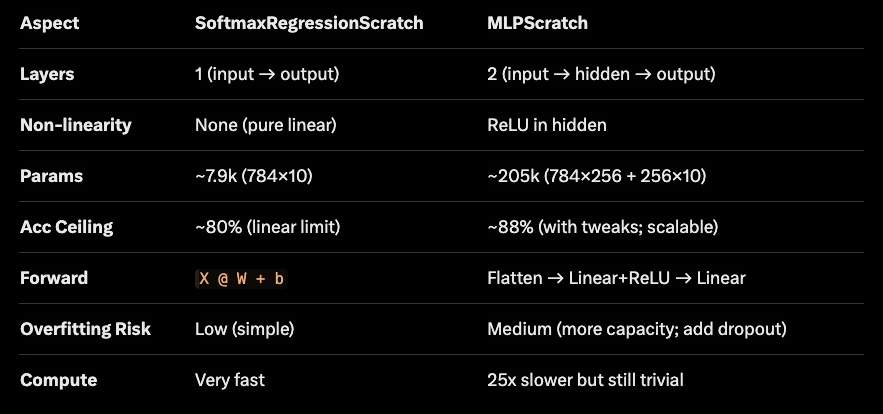

In [ ]:
# Plot for a single model (e.g., MLP; repeat for softmax)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

epochs = range(1, len(train_losses_m) + 1)

ax1.plot(epochs, train_losses_m, 'b-', label='Train Loss')
ax1.plot(epochs, val_losses_m, 'r-', label='Val Loss')
ax1.set_title('MLP: Loss Over Epochs')
ax1.set_xlabel('Epoch')
ax1.set_ylabel('Loss')
ax1.legend()
ax1.grid(True)

ax2.plot(epochs, train_accs_m, 'b-', label='Train Acc')
ax2.plot(epochs, val_accs_m, 'r-', label='Val Acc')
ax2.set_title('MLP: Accuracy Over Epochs')
ax2.set_xlabel('Epoch')
ax2.set_ylabel('Accuracy (%)')
ax2.legend()
ax2.grid(True)

plt.tight_layout()
plt.show()

# Compare both models side-by-side
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

# Loss comparison
ax1.plot(epochs, train_losses_s, 'b--', label='Softmax Train')
ax1.plot(epochs, val_losses_s, 'r--', label='Softmax Val')
ax1.plot(epochs, train_losses_m, 'b-', label='MLP Train')
ax1.plot(epochs, val_losses_m, 'r-', label='MLP Val')
ax1.set_title('Loss Comparison: Softmax vs. MLP')
ax1.set_xlabel('Epoch')
ax1.set_ylabel('Loss')
ax1.legend()
ax1.grid(True)

# Acc comparison
ax2.plot(epochs, train_accs_s, 'b--', label='Softmax Train')
ax2.plot(epochs, val_accs_s, 'r--', label='Softmax Val')
ax2.plot(epochs, train_accs_m, 'b-', label='MLP Train')
ax2.plot(epochs, val_accs_m, 'r-', label='MLP Val')
ax2.set_title('Accuracy Comparison: Softmax vs. MLP')
ax2.set_xlabel('Epoch')
ax2.set_ylabel('Accuracy (%)')
ax2.legend()
ax2.grid(True)

plt.tight_layout()
plt.show()

In [ ]:
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns

def get_predictions(model, loader):
    model.eval()
    all_preds = []
    all_labels = []
    with torch.no_grad():
        for X, y in loader:
            y_hat = model(X)
            preds = torch.argmax(y_hat, dim=1)
            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(y.cpu().numpy())
    return np.array(all_preds), np.array(all_labels)

preds_m, true_m = get_predictions(model_m, test_loader)
cm_m = confusion_matrix(true_m, preds_m)
print('MLP Confusion Matrix:')
print(classification_report(true_m, preds_m, target_names=labels))

# Plot heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(cm_m, annot=True, fmt='d', cmap='Blues', xticklabels=labels, yticklabels=labels)
plt.title('MLP Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('True')
plt.xticks(rotation=45)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()